# Challenger O-rings: what went wrong

We take up the Challenger analysis  and correct its three problems:   
(c) flights without incident were removed.   
(b) the prediction at 31 °F is far outside the tested range.    
(e) the uncertainty of the estimate was ignored.  

In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from sklearn.linear_model import LogisticRegression

data = pd.read_csv("shuttle.csv")
data["Frequency"] = data.Malfunction / data.Count
data

,Date,Count,Temperature,Pressure,Malfunction,Frequency
0,4/12/81,6,66,50,0,0.000000
1,11/12/81,6,70,50,1,0.166667
2,3/22/82,6,69,50,0,0.000000
3,11/11/82,6,68,50,0,0.000000
4,4/04/83,6,67,50,0,0.000000
5,6/18/82,6,72,50,0,0.000000
6,8/30/83,6,73,100,0,0.000000
7,11/28/83,6,70,100,0,0.000000
8,2/03/84,6,57,200,1,0.166667
9,4/06/84,6,63,200,1,0.166667


## Keeping all the flights

Flights without incident do carry information: most of them took place at high temperature. As in the challenger analysis, we assume that each of the 6 O-rings fails independently with probability p(t), and fit a logistic regression, once on the failure-only flights (original analysis) and once on all flights.

In [60]:
def fit(df):
    # one row per O-ring: 1 = malfunction, 0 = ok
    X = np.repeat(df.Temperature.values, 6).reshape(-1, 1)
    y = np.concatenate([[1]*k + [0]*(6-k) for k in df.Malfunction])
    return LogisticRegression(C=1e10, max_iter=10000).fit(X, y), X

model_nasa, _ = fit(data[data.Malfunction > 0])
model, X = fit(data)
print("temperature coefficient, failure-only flights:", model_nasa.coef_[0][0])
print("temperature coefficient, all flights:         ", model.coef_[0][0])

temperature coefficient, failure-only flights: 0.001415900281101442
temperature coefficient, all flights:          -0.11560105285057665


With the failure-only flights the coefficient is almost zero, which is why the challenger analysis concluded that temperature has no effect. With all flights it is clearly negative: the colder, the higher the risk.

## Confidence interval

We compute a 95 % (Wald) confidence interval on the logit scale and look at the launch temperature, 31 °F.

In [61]:
p = model.predict_proba(X)[:, 1]
A = np.c_[np.ones(len(X)), X]
cov = np.linalg.inv(A.T @ (A * (p * (1 - p))[:, None]))

t = np.linspace(31, 85, 109)
T = np.c_[np.ones(len(t)), t]
eta = T @ np.r_[model.intercept_, model.coef_[0]]
se = np.sqrt(np.sum(T @ cov * T, axis=1))
low, high = expit(eta - 1.96 * se), expit(eta + 1.96 * se)

print("p(31 F) =", expit(eta[0]), "  95% CI:", low[0], high[0])

p(31 F) = 0.8177738308213031   95% CI: 0.1595929533429418 0.9906587886932717


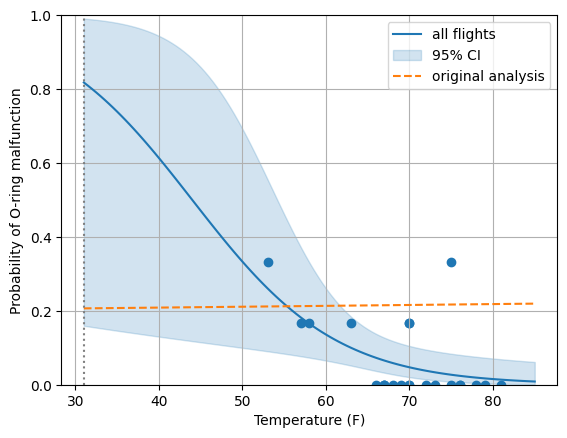

In [62]:
plt.scatter(data.Temperature, data.Frequency)
plt.plot(t, expit(eta), label="all flights")
plt.fill_between(t, low, high, color="C0", alpha=0.2, label="95% CI")
plt.plot(t, model_nasa.predict_proba(t.reshape(-1, 1))[:, 1], "--", label="original analysis")
plt.axvline(31, color="grey", linestyle=":")
plt.xlabel("Temperature (F)")
plt.ylabel("Probability of O-ring malfunction")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)

## Risk for the shuttle

The Challenger analysis uses p = 0.065 whatever the temperature, which gives 1 − (1 − p²)³ for the failure of a launcher. With the probability at 31 °F the result is very different:

In [63]:
shuttle = lambda p: 1 - (1 - p**2)**3
p0 = data.Malfunction.sum() / data.Count.sum()
print("original analysis:", shuttle(p0))
print("at 31 F:          ", shuttle(expit(eta[0])), "  95% CI:", shuttle(low[0]), shuttle(high[0]))

original analysis: 0.01270572944054793
at 31 F:           0.9636544055070673   95% CI: 0.07448010595594279 0.9999935701614836


## Conclusion

- Removing the flights without incident hides the effect of temperature (error c).
- At 31 °F, 22 °F below the coldest test, the model gives about 82 % per O-ring instead of 6.5 %, and about 96 % for the shuttle instead of 1.3 % (error b).
- This estimate is very uncertain (95 % CI from 16 % to 99 %), which alone should have been enough to postpone the launch (error e).